# Hugoniot Fits: Stishovite

In [1]:
%%capture 
## This cell loads the modules, data, and EOS parameters
## capture magic function hides the output; comment out to see diagnostic info during data load
## Run executable notebook for output

%run -i scripts/set_paths
%run -i scripts/load_modules
%run -i scripts/load_silica_data
%run -i scripts/define_mc
%run -i scripts/define_eos
%run -i scripts/calibrate_decaying_shocks.py
%run -i scripts/load_vapor_domes.py
%run -i scripts/load_liquid_model.py
%run -i scripts/load_solid_models.py
#%run -i scripts/hugoniot-entropy.py
%run -i scripts/intersection.py # intersection function
##%run -i scripts/odr_models.py # ODR and model functions # REMOVE 
%run -i scripts/set_plotstyle.py # customize matplotlib
%run -i scripts/set_colors.py # custom colors

# this notebook's figure name tag
tag = 'STV-'


## Load data

## Fit linear Hugoniot in liquid region

FIT EOS a =  [7.13305468 1.30849513]
FIT EOS cov =  [[ 1.30433373 -0.09247795]
 [-0.09247795  0.00676061]]
Saved EOS fit in stv_fit_liq_linear_up18.txt
Saved EOS fit in readable file stv_fit_liq_linear_up18-readable.txt
rms =  0.23534310351489302
stv_fit_liqalt check:
Coefficients are the same.
[7.13305468 1.30849513]
[7.13305468 1.30849513]


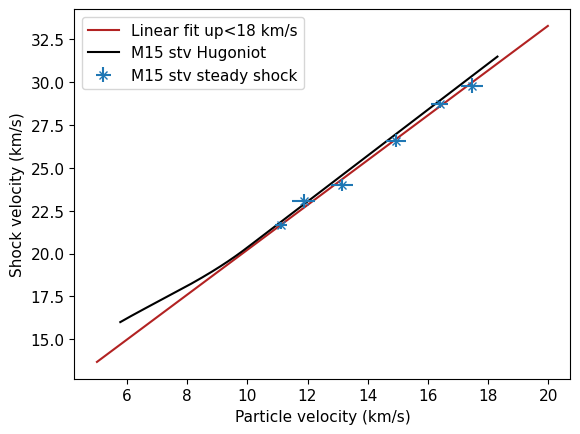

In [2]:
fitx = shockdat[iM15stvhug.i].up
fitf= shockdat[iM15stvhug.i].us
fitx_std = shockdat[iM15stvhug.i].up_std
fitf_std = shockdat[iM15stvhug.i].us_std
fitrefid = np.full(len(fitx), shockdat[iM15stvhug.i].refidlist[1], dtype=int)
fitreflist=[]
for i in np.unique(fitrefid):
    fitreflist.append(str(i)+': '+ref_list[i].reference[0])


# initialize the HPeos_Fit class
stv_fit_liq = hp.HPeos_Fit()
stv_fit_liq.matid = 149
stv_fit_liq.material = 'Stishovite'
stv_fit_liq.formula = 'SiO2'
stv_fit_liq.rho_ref = 4.29
stv_fit_liq.rho_ref_std = 0.03
stv_fit_liq.rho_ref_units = 'g/cm³'
stv_fit_liq.x = fitx
stv_fit_liq.f = fitf
stv_fit_liq.x_std = fitx_std
stv_fit_liq.f_std = fitf_std
stv_fit_liq.refid = fitrefid
stv_fit_liq.reflist = fitreflist
stv_fit_liq.x_var = 'up'
stv_fit_liq.f_var = 'us'
stv_fit_liq.x_units = 'km/s'
stv_fit_liq.f_units = 'km/s'
stv_fit_liq.x_desc = 'Particle Velocity'
stv_fit_liq.f_desc = 'Shock Velocity'
stv_fit_liq.phase_fit = 'liquid'
stv_fit_liq.remlist.append('Fit to liquid region on the Hugoniot.')
DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
stv_fit_liq.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]

stv_fit_liq.curvetype = 'linear'
stv_fit_liq.outputfitpath = outputfitpath # in load_paths.py
stv_fit_liq.filename = 'stv_fit_liq_linear'
stv_fit_liq.fit()
#print('FIT EOS a = ',stv_fit_liq.a)
#print('FIT EOS cov = ',stv_fit_liq.cov)
#stv_fit_liq.savejson()
#stv_fit_liq.savereadable()
#print('rms = ',stv_fit_liq.rms)

if 1:
    ind = np.where(shockdat[iM15stvhug.i].up<18)
    fitx = shockdat[iM15stvhug.i].up[ind]
    fitf= shockdat[iM15stvhug.i].us[ind]
    fitx_std = shockdat[iM15stvhug.i].up_std[ind]
    fitf_std = shockdat[iM15stvhug.i].us_std[ind]
    fitrefid = np.full(len(fitx), shockdat[iM15stvhug.i].refidlist[1], dtype=int)
    fitreflist=[]
    for i in np.unique(fitrefid):
        fitreflist.append(str(i)+': '+ref_list[i].reference[0])
    
    
    # initialize the HPeos_Fit class
    stv_fit_liqalt = hp.HPeos_Fit()
    stv_fit_liqalt.matid = 149
    stv_fit_liqalt.material = 'Stishovite'
    stv_fit_liqalt.formula = 'SiO2'
    stv_fit_liqalt.rho_ref = 4.29
    stv_fit_liqalt.rho_ref_std = 0.03
    stv_fit_liqalt.rho_ref_units = 'g/cm³'
    stv_fit_liqalt.x = fitx
    stv_fit_liqalt.f = fitf
    stv_fit_liqalt.x_std = fitx_std
    stv_fit_liqalt.f_std = fitf_std
    stv_fit_liqalt.refid = fitrefid
    stv_fit_liqalt.reflist = fitreflist
    stv_fit_liqalt.x_var = 'up'
    stv_fit_liqalt.f_var = 'us'
    stv_fit_liqalt.x_units = 'km/s'
    stv_fit_liqalt.f_units = 'km/s'
    stv_fit_liqalt.x_desc = 'Particle Velocity'
    stv_fit_liqalt.f_desc = 'Shock Velocity'
    stv_fit_liqalt.phase_fit = 'liquid'
    stv_fit_liqalt.remlist.append('Fit to liquid region on the Hugoniot for up<18km/s.')
    DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
    stv_fit_liqalt.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]
    
    stv_fit_liqalt.curvetype = 'linear'
    stv_fit_liqalt.outputfitpath = outputfitpath # in load_paths.py
    stv_fit_liqalt.filename = 'stv_fit_liq_linear_up18'
    stv_fit_liqalt.fit()
    print('FIT EOS a = ',stv_fit_liqalt.a)
    print('FIT EOS cov = ',stv_fit_liqalt.cov)
    stv_fit_liqalt.savejson()
    stv_fit_liqalt.savereadable()
    print('rms = ',stv_fit_liqalt.rms)

    print('stv_fit_liqalt check:')
    stv_fit_liqalt.comparecoefs(stv_fit_liq0.a)


#plt.plot(fitx,fitf,'kx',markersize=10)
nup = np.arange(5,20,.01)
nus = stv_fit_liq.calcf(nup)
nusalt = stv_fit_liqalt.calcf(nup)
plt.plot(nup,nusalt,'-',color='firebrick',label='Linear fit up<18 km/s')
#plt.plot(nup,nus,'-',color='cyan',label='linear all')
#plt.plot(m15dat[:,5],m15dat[:,0],'k-',label='M15 stv Hugoniot')
plt.plot(shockdat[iM15stv.i].up,shockdat[iM15stv.i].us,'k-',label='M15 stv Hugoniot')
plt.errorbar(fitx,fitf,xerr=fitx_std,yerr=fitf_std,fmt='x',label=iM15stvhug.label+' steady shock')

plt.xlabel('Particle velocity (km/s)')
plt.ylabel('Shock velocity (km/s)')
plt.legend()
plt.show()

## Fit Us-T above the plateau

FIT EOS a =  [-5.44165475e+05  9.65787826e+04 -6.37860228e+03  1.87083998e+02
 -1.98924995e+00]
FIT EOS cov =  [[ 1.55036691e+10 -2.70732590e+09  1.75125081e+08 -4.97215408e+06
   5.22781598e+04]
 [-2.70732590e+09  4.73407959e+08 -3.06646881e+07  8.71821642e+05
  -9.17877345e+03]
 [ 1.75125081e+08 -3.06646881e+07  1.98905715e+06 -5.66296613e+04
   5.97036167e+02]
 [-4.97215408e+06  8.71821642e+05 -5.66296613e+04  1.61456180e+03
  -1.70459683e+01]
 [ 5.22781598e+04 -9.17877345e+03  5.97036167e+02 -1.70459683e+01
   1.80218695e-01]]
Saved EOS fit in stv_fitTus_liq_fourthpoly.txt
Saved EOS fit in readable file stv_fitTus_liq_fourthpoly-readable.txt
rms =  114.70518118417486
stv_fitTus_liq check:
Coefficients are the same.
[-5.44165475e+05  9.65787826e+04 -6.37860228e+03  1.87083998e+02
 -1.98924995e+00]
[-5.44165475e+05  9.65787826e+04 -6.37860228e+03  1.87083998e+02
 -1.98924995e+00]


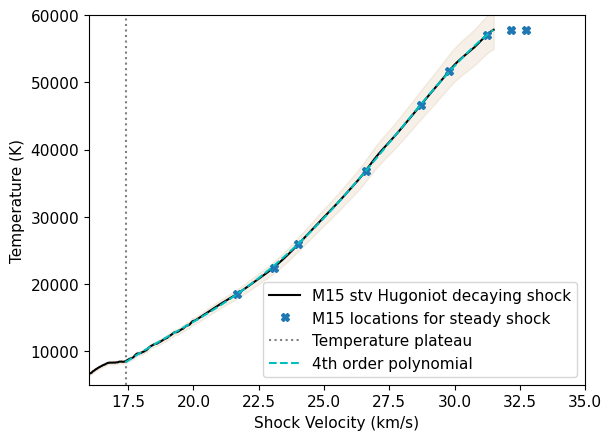

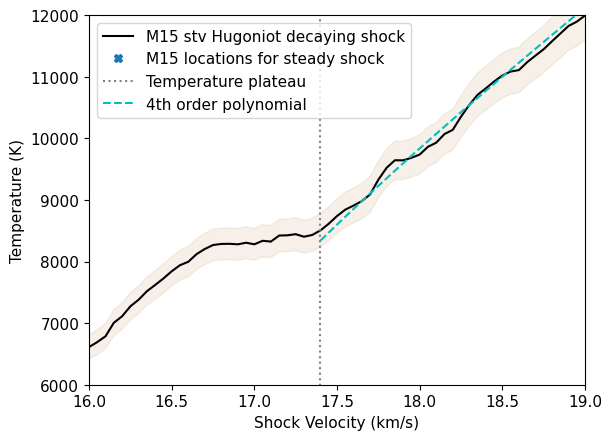

In [3]:
###stv_wiggle2.us is set in define_eos.py

for ii in [1,2]:
#    plt.plot(m15dat[:,0],m15dat[:,1],'k-',label='M15 stv Hugoniot')
#    plt.fill_between(m15dat[:,0],m15dat[:,1]-m15dat[:,2],m15dat[:,1]+m15dat[:,2],color='tan',alpha=.2)

    plt.plot(shockdat[iM15stv.i].us,shockdat[iM15stv.i].T,'k-',label='M15 stv Hugoniot decaying shock')
    plt.fill_between(shockdat[iM15stv.i].us,shockdat[iM15stv.i].T-shockdat[iM15stv.i].T_std,shockdat[iM15stv.i].T+shockdat[iM15stv.i].T_std,color='tan',alpha=0.2)

    plt.plot(shockdat[iM15stvhug.i].us,np.interp(shockdat[iM15stvhug.i].us,shockdat[iM15stv.i].us,shockdat[iM15stv.i].T),'X',label='M15 locations for steady shock')
    plt.plot([stv_wiggle2.us,stv_wiggle2.us],[0,60000],':',color='grey',label='Temperature plateau')

    if 0:
        ind = np.where(m15dat[:,0]>stv_wiggle2.us)[0]
        res = np.polyfit(m15dat[ind,0],m15dat[ind,1],3)
        yfit = res[3]+res[2]*m15dat[ind,0]+res[1]*m15dat[ind,0]*m15dat[ind,0]+res[0]*m15dat[ind,0]*m15dat[ind,0]*m15dat[ind,0]
        #plt.plot(m15dat[ind,0],yfit,'r--',label='n=3')
        res = np.polyfit(m15dat[ind,0],m15dat[ind,1],4)
        #print(res)
        yfit = np.zeros(len(m15dat[ind,0]))
        for i in range(len(res)-1,-1,-1):
            #print(i,res[i],len(res)-i-1)
            yfit +=res[i]*np.pow(m15dat[ind,0],len(res)-i-1)
        #plt.plot(m15dat[ind,0],yfit,'r--',label='4th order polynomial')
    if ii==1:
        ind = np.where(shockdat[iM15stv.i].us>stv_wiggle2.us)[0]
#        ind = np.where((shockdat[iM15stv.i].us>stv_wiggle2.us) & (shockdat[iM15stv.i].us<28))[0]
        fitx = shockdat[iM15stv.i].us[ind]
        fitf= shockdat[iM15stv.i].T[ind]
        fitx_std = shockdat[iM15stv.i].us_std[ind]
        fitf_std = shockdat[iM15stv.i].T_std[ind]
        fitrefid = np.full(len(fitx), shockdat[iM15stv.i].refidlist[1], dtype=int)
        fitreflist=[]
        for i in np.unique(fitrefid):
            fitreflist.append(str(i)+': '+ref_list[i].reference[0])
        
        # initialize the HPeos_Fit class
        stv_fitTus_liq = hp.HPeos_Fit()
        stv_fitTus_liq.matid = 149
        stv_fitTus_liq.material = 'Stishovite'
        stv_fitTus_liq.formula = 'SiO2'
        stv_fitTus_liq.rho_ref = 4.29
        stv_fitTus_liq.rho_ref_std = 0.03
        stv_fitTus_liq.rho_ref_units = 'g/cm³'
        stv_fitTus_liq.x = fitx
        stv_fitTus_liq.f = fitf
        stv_fitTus_liq.x_std = fitx_std
        stv_fitTus_liq.f_std = fitf_std
        stv_fitTus_liq.refid = fitrefid
        stv_fitTus_liq.reflist = fitreflist
        stv_fitTus_liq.x_var = 'us'
        stv_fitTus_liq.f_var = 'T'
        stv_fitTus_liq.x_units = 'km/s'
        stv_fitTus_liq.f_units = 'K'
        stv_fitTus_liq.x_desc = 'Shock Velocity'
        stv_fitTus_liq.f_desc = 'Temperature'
        stv_fitTus_liq.phase_fit = 'liquid'
        stv_fitTus_liq.remlist.append('Fit to liquid region on the Hugoniot above the temperature plateau: Us>17.3 km/s.')
        DateTime_in_ISOFormat = datetime.datetime.now(zoneinfo.ZoneInfo('UTC')).isoformat('T', 'seconds') #
        stv_fitTus_liq.actions = [['Sarah T. Stewart','create',DateTime_in_ISOFormat,'new fit']]
        
        stv_fitTus_liq.curvetype = 'fourthpoly'
        stv_fitTus_liq.outputfitpath = outputfitpath # in load_paths.py
        stv_fitTus_liq.filename = 'stv_fitTus_liq_fourthpoly'
        stv_fitTus_liq.fit()
        print('FIT EOS a = ',stv_fitTus_liq.a)
        print('FIT EOS cov = ',stv_fitTus_liq.cov)
        stv_fitTus_liq.savejson()
        stv_fitTus_liq.savereadable()
        print('rms = ',stv_fitTus_liq.rms)
        #plt.errorbar(fitx,fitf,xerr=fitx_std,yerr=fitf_std,fmt='x',label=iM15stv.label)

        us_var = np.arange(stv_wiggle2.us,max(shockdat[iM15stv.i].us),.01)
        T_var = stv_fitTus_liq.calcf(us_var)

        print('stv_fitTus_liq check:')
        stv_fitTus_liq.comparecoefs(stv_fitTus_liq0.a)

    plt.plot(us_var,T_var,'c--',label='4th order polynomial')    
    if ii==1:
        plt.xlim(16,35)
        plt.ylim(5000,60000)
    if ii==2:
        plt.xlim(16,19)
        plt.ylim(6000,12000)
    plt.xlabel('Shock Velocity (km/s)')
    plt.ylabel('Temperature (K)')
    plt.legend()
    plt.show()
    #plt.plot(m15dat[ind,0],yfit)


## Using the linear fit to up<18 km/s

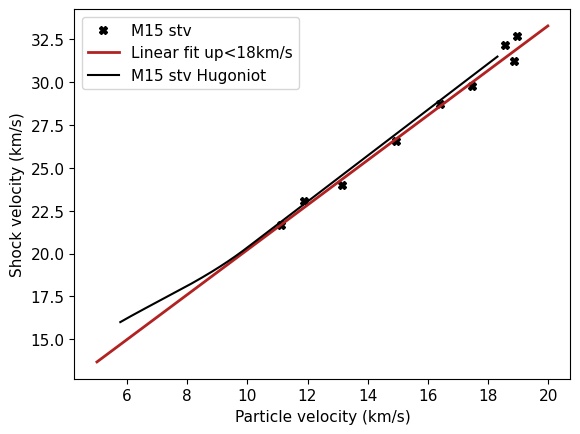

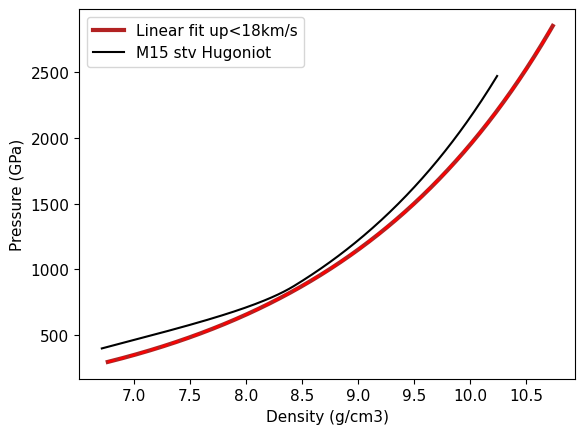

Pressure above the plateau:  585.7007426100024


In [4]:
plt.plot(shockdat[iM15stvhug.i].up,shockdat[iM15stvhug.i].us,'kX',label=iM15stvhug.label)
#plt.plot(shockdat[iM15stvhug.i].up,shockdat[iM15stvhug.i].uflyer,'+',label=iM15stvhug.label)
res,cov = np.polyfit(shockdat[iM15stvhug.i].up,shockdat[iM15stvhug.i].us,1,cov=True)


uparr = nup#np.arange(5,20,.1)
usarr = nusalt#res[1]+res[0]*uparr
parr = 4.29*uparr*usarr
rarr = 1/((1/4290)*(1-uparr/usarr))/1000
plt.plot(uparr,usarr,'-',color='firebrick',linewidth=2,label='Linear fit up<18km/s')
#plt.plot(m15dat[:,5],m15dat[:,0],'k-',label='M15 stv Hugoniot')
plt.plot(shockdat[iM15stv.i].up,shockdat[iM15stv.i].us,'k-',label='M15 stv Hugoniot')

plt.xlabel('Particle velocity (km/s)')
plt.ylabel('Shock velocity (km/s)')
plt.legend()

plt.show()
plt.plot(rarr,parr,'-',color='firebrick',linewidth=3,label='Linear fit up<18km/s')
#plt.plot(m15dat[:,3],m15dat[:,4],'k-',label='M15 stv Hugoniot')
plt.plot(shockdat[iM15stv.i].rho,shockdat[iM15stv.i].P,'k-',label='M15 stv Hugoniot')
plt.plot(stv_hug_liq.rho,stv_hug_liq.P,'r--')
plt.xlabel('Density (g/cm3)')
plt.ylabel('Pressure (GPa)')
plt.legend()

plt.show()

stv_wiggle_P2 =np.interp(stv_wiggle2.us,usarr,parr)
print('Pressure above the plateau: ',stv_wiggle_P2)
#print(shockdat[iM15stvhug.i].uflyer)

Hugoniot crosses melt curve near the pyrite-cotunnite-liquid triple point from G16


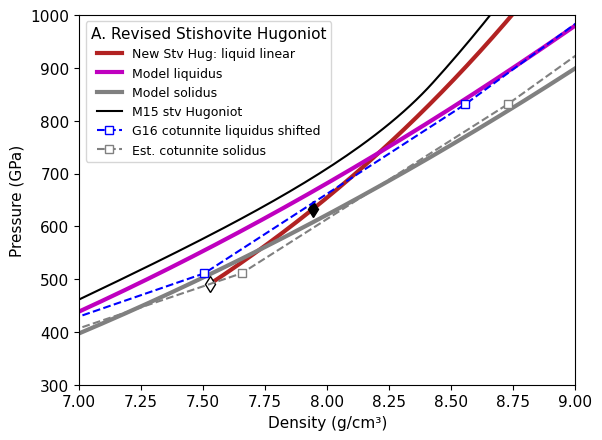

In [5]:
# estimate stv solidus using density information from G16

#plt.plot(stv_hug_liq.rho,stv_hug_liq.P,'k-',label='New Stv Hugoniot')
ind = np.where(parr>= stv_solidus_P)
plt.plot(rarr[ind],parr[ind],'-',color='firebrick',linewidth=3,label='New Stv Hug: liquid linear')

plt.plot(stsmcsmooth.rho,stsmcsmooth.P,color='m',linewidth=3,label='Model liquidus')
plt.plot(stsmcsmooth.rho_s,stsmcsmooth.P,color=colsolidus,linewidth=3,label='Model solidus')
plt.errorbar(eosdat_list[G16mc['id']].rho_l[1:8]+pbe_liquid_density_shift,eosdat_list[G16mc['id']].P[1:8],fmt='s--',mfc='white',mec='b',color='b',label='G16 cotunnite liquidus shifted') # cotunnite structure
plt.errorbar((eosdat_list[G16mc['id']].rho_l[1:8]+pbe_liquid_density_shift)*1.02,eosdat_list[G16mc['id']].P[1:8],fmt='s--',mfc='white',mec='grey',color='grey',label='Est. cotunnite solidus') # cotunnite structure

plt.plot(np.interp(stv_solidus_P,parr,rarr),stv_solidus_P,'kd',mfc='white',markersize=8)
plt.plot(np.interp(stv_liquidus_P,parr,rarr),stv_liquidus_P,'kd',markersize=8)

plt.plot(shockdat[iM15stv.i].rho,shockdat[iM15stv.i].P,'k-',label='M15 stv Hugoniot')

plt.legend(fontsize=lfss,title='A. Revised Stishovite Hugoniot')
plt.ylim(300,1000)
plt.xlim(7,9.)
plt.xlabel('Density (g/cm³)')
plt.ylabel('Pressure (GPa)')
plt.savefig(figurefigpath+'stv-melt-crossing2.pdf')

print('Hugoniot crosses melt curve near the pyrite-cotunnite-liquid triple point from G16')



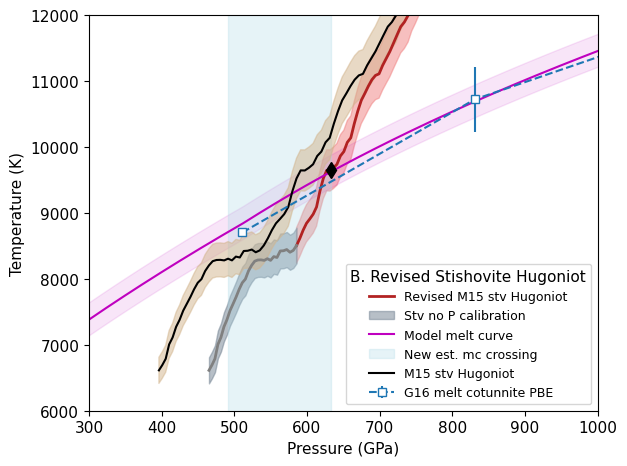

In [7]:

ind = np.where((stv_hug_M15rev.us>stv_wiggle2.us*0.999))[0]
plt.plot(stv_hug_M15rev.P[ind],stv_hug_M15rev.T[ind],'-',linewidth=2,color='firebrick',label='Revised M15 stv Hugoniot')#,label='Stv no calibration')
plt.fill_between(stv_hug_M15rev.P[ind],stv_hug_M15rev.T[ind]-stv_hug_M15rev.T_std[ind],stv_hug_M15rev.T[ind]+stv_hug_M15rev.T_std[ind],color='lightcoral',alpha=0.5)
ind = np.where((stv_hug_M15rev.us<stv_wiggle2.us*1.0001))[0]
plt.plot(stv_hug_M15rev.P[ind],stv_hug_M15rev.T[ind],'-',linewidth=2,color='grey')#,label='Stv no calibration')
plt.fill_between(stv_hug_M15rev.P[ind],stv_hug_M15rev.T[ind]-stv_hug_M15rev.T_std[ind],stv_hug_M15rev.T[ind]+stv_hug_M15rev.T_std[ind],color='slategrey',alpha=0.5,label='Stv no P calibration')

# Gonzales et al. 2016 very high pressure melt curve points
#plt.errorbar(eosdat_list[G16mc['id']].P[1:4],eosdat_list[G16mc['id']].T[1:4],fmt='d--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[1:4],label=G16mc['lab']) # pyrite structure
plt.errorbar(eosdat_list[G16mc['id']].P[5:8],eosdat_list[G16mc['id']].T[5:8],fmt='s--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[5:8],label=G16mcb['lab']) # cotunnite structure
#plt.errorbar(eosdat_list[G16mc['id']].P[8:11],eosdat_list[G16mc['id']].T[8:11],fmt='o--',mfc='white',yerr=eosdat_list[G16mc['id']].T_std[8:11],label=G16mcc['lab']) # Fe2P structure
#plt.plot(eosdat_list[G24mcl['id']].P_liquid,eosdat_list[G24mcl['id']].T_liquid,'r+',label=G24mcl['lab'])
#plt.plot(eosdat_list[G24mcs['id']].P_solid,eosdat_list[G24mcs['id']].T_solid,'rx',label=G24mcs['lab'])
#plt.fill_between(eosdat_list[G16mc['id']].P[5:8],eosdat_list[G16mc['id']].T[5:8]-500,eosdat_list[G16mc['id']].T[5:8]+500,color='gold',alpha=0.3)

plt.plot(stsmcsmooth.P,stsmcsmooth.T,'m-',label='Model melt curve')
plt.fill_between(stsmcsmooth.P,stsmcsmooth.T-250,stsmcsmooth.T+250,color='m',alpha=0.1)

if 0:
    pg24arr = np.arange(440)+60 # GPa
    tg24arr = 6.426*np.power((1+(pg24arr+256.011)/6.474e-04),0.5141)
    #plt.plot(pg24arr,tg24arr,'--',color='orange',label='G24 melt curve\n(Z method PBE)',linewidth=2)
    pg24arr = np.arange(440)+50 # GPa
    tg24arr = 6.018*np.power((1+(pg24arr+202.338)/4.736e-04),0.5126)
    #plt.plot(pg24arr,tg24arr,'r-',label='G24 2phase PBE')
    pg24arr = np.arange(440)+50 # GPa
    tg24arr = 6.018*np.power((1+(pg24arr+202.338)/4.736e-04),0.5126)
    plt.plot(pg24arr,tg24arr,'-',color='m',label='G24 2phase PBE')
    plt.fill_between(pg24arr,tg24arr-200,tg24arr+200,color='m',alpha=0.1)


#plt.plot(stv_hug_M15rev.P,stv_hug_M15rev.T,'-',color='firebrick',linewidth=2,label='Revised M15 stv Hugoniot')
#plt.fill_between(stv_hug_M15rev.P,stv_hug_M15rev.T-stv_hug_M15rev.T_std,stv_hug_M15rev.T+stv_hug_M15rev.T_std,color='lightcoral',alpha=0.5)


#stv_hug_liq.T_std = np.interp(stv_hug_liq.us,shockdat[iM15stv.i].us,shockdat[iM15stv.i].T_std)
#plt.plot(stv_hug_liq.P,stv_hug_liq.T,'r-',label='New stv Hugoniot')
#plt.fill_between(stv_hug_liq.P,stv_hug_liq.T-stv_hug_liq.T_std,stv_hug_liq.T+stv_hug_liq.T_std,color='red',alpha=0.1)

if 0:
    ind = np.where((stv_hug_M15rev.us<33) & (stv_hug_M15rev.us>stv_wiggle2.us))[0]
    plt.plot(stv_hug_M15rev.P[ind],stv_hug_M15rev.T,'-',color='firebrick',label='New stv linear Hugoniot')
    plt.fill_between(stv_hug_M15rev.P[ind],m15dat[ind,1]-m15dat[ind,2],m15dat[ind,1]+m15dat[ind,2],color='lightcoral',alpha=0.5)
    ind = np.where((m15dat[:,0]<stv_wiggle2.us*1.0001))[0]
    plt.plot(m15datpnew[ind],m15dat[ind,1],'-',color='slategrey')#,label='Stv no calibration')
    plt.fill_between(m15datpnew[ind],m15dat[ind,1]-m15dat[ind,2],m15dat[ind,1]+m15dat[ind,2],color='slategrey',alpha=0.5,label='Stv no P calibration')

plt.fill_between([stv_solidus_P,stv_liquidus_P],[0,0],[20000,20000],color='lightblue',alpha=0.3,label='New est. mc crossing')

#plt.plot(stv_solidus_P,np.interp(stv_solidus_P,stv_hug_M15rev.P,stv_hug_M15rev.T),'kd',mfc='white',markersize=8)
plt.plot(stv_liquidus_P,np.interp(stv_liquidus_P,stv_hug_M15rev.P,stv_hug_M15rev.T),'kd',markersize=8)
#plt.plot(np.interp(stv_liquidus_P,parr,rarr),stv_liquidus_P,'kd',markersize=8)
plt.plot(shockdat[iM15stv.i].P,shockdat[iM15stv.i].T,'k-',label='M15 stv Hugoniot')
plt.fill_between(shockdat[iM15stv.i].P,shockdat[iM15stv.i].T-shockdat[iM15stv.i].T_std,shockdat[iM15stv.i].T+shockdat[iM15stv.i].T_std,color='tan',alpha=0.5)

plt.legend(fontsize=lfss,title='B. Revised Stishovite Hugoniot')
plt.xlim(300,1000)
plt.ylim(6000,12000)
plt.xlabel('Pressure (GPa)')
plt.ylabel('Temperature (K)')
plt.tight_layout()
plt.savefig(outputfigpath+'stv-melt-crossing3.pdf')
plt.savefig(figurefigpath+'stv-melt-crossing3.pdf')
plt.show()